# Анализ факторов, влияющих на время госпитализации в ФГБОУ ВО СПбГПМУ
- Автор: Наталья Пронько
- Дата: 15.08.2026

## Цель проекта

Провести комплексный анализ данных федерального медицинского центра ФГБОУ ВО СПбГПМУ для выявления факторов, влияющих на длительность процесса госпитализации — от выдачи направления до поступления пациента в медицинский центр. По результатам анализа сформулировать практические рекомендации для руководства центра по оптимизации сроков и повышению эффективности работы отделений.

---

## Задачи проекта

### Шаг 1. Подготовка данных
- Загрузить датасет `hospital.csv` и сохранить исходные данные в отдельный датафрейм.
- Провести ревизию названий столбцов: предложить и применить более удобные и информативные метки (например, `admission_date`, `discharge_date`, `patient_id`, `region`, `department`, `bed_days` и т.д.).
- Выявить и обработать пропуски в данных: определить столбцы с пропусками, оценить их долю, выбрать стратегию обработки (удаление, заполнение, обоснование оставления).
- Проверить корректность типов данных (даты, категориальные признаки, числовые поля) и при необходимости привести их к нужным типам.
- Обнаружить и удалить дубликаты записей, а также обосновать критерии их выявления.

### Шаг 2. Исследовательский анализ данных (EDA)
- Изучить распределение длительности госпитализации пациентов с помощью гистограммы и диаграммы "ящик с усами", описать форму распределения, наличие выбросов и аномалий.
- Рассчитать среднюю длительность госпитализации по отделениям и выделить топ-10 отделений с наибольшей средней длительностью лечения; визуализировать результат.
- Исследовать динамику количества поступивших пациентов по месяцам с учетом различий между годами (сезонность, тренды, пики нагрузки).

### Шаг 3. Проверка гипотез
- Гипотеза 1 (руководство): проверить статистически, отличается ли средняя длительность госпитализации от стандартного семидневного срока (одновыборочный t-тест).
- Гипотеза 2 (медицинский отдел): проверить, превышает ли средняя длительность госпитализации 10 дней (односторонний t-тест).
- Гипотеза 3: проверить, различается ли средняя длительность лечения между плановыми и экстренными пациентами (двухвыборочный t-тест / тест Манна-Уитни в зависимости от распределения).
- Для каждой гипотезы сформулировать нулевую и альтернативную гипотезы, выбрать уровень значимости, интерпретировать p-value и сделать содержательный вывод.

## Ожидаемые результаты
1. Подготовленный и очищенный датафрейм, пригодный для анализа.
2. Набор визуализаций, отражающих распределение длительности госпитализации, нагрузку по отделениям и сезонную динамику поступлений.
3. Статистически обоснованные выводы по трем проверяемым гипотезам.
4. Итоговый отчет с рекомендациями по оптимизации сроков госпитализации и управлению нагрузкой на отделения.

## Описание данных
Будем работать с таблицей `hospital.csv` — в ней данные федерального медицинского центра ФГБОУ ВО СПбГПМУ.
Поля таблицы `hospital.csv` :

 - `ДАТА_ПОСТУПЛЕНИЯ` — дата поступления пациента в отделение;
 - `ДАТА_ВЫПИСКИ` — дата выписки пациента из отделения;
 - `УНИКАЛЬНЫЙ_ID` — идентификатор пациента;
 - `НОМЕР_ИБ` — системное поле (номер информационной безопасности);
 - `ШИФР` — системное поле;
 - `РЕГИОН` — регион проживания пациента;
 - `ПЛАТЕЛЬЩИК` — наименование плательщика;
 - `ИСТОЧНИК_ФИНАНСИРОВАНИЯ— ОМС` или другой вариант;
 - `ОТДЕЛЕНИЕ`— название отделения;
 - `ПРОФИЛЬ` — профиль отделения (например, терапия, хирургия);
 - `КОЙКО_ДНИ`— количество дней лечения в стационаре;
 - `ПЛАНОВО_ЭКСТРЕННО`— поступил планово или экстренно;
 - `КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ`— код диагноза при поступлении;
 - `КОД_МКБ_ПРИ_ВЫПИСКЕ`— код диагноза при выписке.

## 1. Подготовка данных

In [2]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

import warnings
warnings.filterwarnings('ignore')

In [3]:
# Выгружаем данные в переменную df_hospital
df_hospital = pd.read_csv('hospital.csv')

In [4]:
# Познакомимся с данными
print('\n---info()---')
df_hospital.info()
print('\n---head()---')
display(df_hospital.head())


---info()---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125261 entries, 0 to 125260
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   ДАТА_ПОСТУПЛЕНИЯ         125261 non-null  object 
 1   ДАТА_ВЫПИСКИ             125261 non-null  object 
 2   УНИКАЛЬНЫЙ_ID            125261 non-null  int64  
 3   НОМЕР_ИБ                 125261 non-null  int64  
 4   ШИФР                     125261 non-null  object 
 5   РЕГИОН                   56391 non-null   object 
 6   ПЛАТЕЛЬЩИК               125261 non-null  object 
 7   ИСТОЧНИК_ФИНАНСИРОВАНИЯ  125261 non-null  object 
 8   ОТДЕЛЕНИЕ                125261 non-null  object 
 9   ПРОФИЛЬ                  125261 non-null  object 
 10  КОЙКО_ДНИ                125261 non-null  float64
 11  ПЛАНОВО_ЭКСТРЕННО        125261 non-null  object 
 12  КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ  125253 non-null  object 
 13  КОД_МКБ_ПРИ_ВЫПИСКЕ      125257 non-null  obj

,ДАТА_ПОСТУПЛЕНИЯ,ДАТА_ВЫПИСКИ,УНИКАЛЬНЫЙ_ID,НОМЕР_ИБ,ШИФР,РЕГИОН,ПЛАТЕЛЬЩИК,ИСТОЧНИК_ФИНАНСИРОВАНИЯ,ОТДЕЛЕНИЕ,ПРОФИЛЬ,КОЙКО_ДНИ,ПЛАНОВО_ЭКСТРЕННО,КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ,КОД_МКБ_ПРИ_ВЫПИСКЕ
0,01.01.2019,10.01.2019,858042000,1,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Микрохирургическое отделение,Сосудистой хирургии,10.0,Экстренная,S61.7,S66.4
1,01.01.2019,01.01.2019,993109000,3,5.13.1,NaN,"СПб филиал ООО ""СМК РЕСО - Мед""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.0,Экстренная,K37,K63.8
2,01.01.2019,01.01.2019,993111000,4,5.12.1,NaN,"ООО ""Капитал Медицинское Страхование""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.0,Экстренная,K37,K63.8
3,01.01.2019,07.01.2019,993110000,2,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Инфекционное отделение №1,Инфекционные,7.0,Экстренная,B27.9,J03.9
4,01.01.2019,05.01.2019,987185000,5,1.1.1,NaN,Коммерческие,Наличный расчет,ПЦ Акушерское физиологическое отделение,Для беременных и рожениц,5.0,Плановая,O42.9,O82.1



В ходе первичного осмотра датасета `hospital.csv` установлено следующее:

**Размер и структура данных**
- Датасет содержит **125 261 запись** и **14 столбцов**, что соответствует достаточному объему для проведения статистического анализа.
- Данные представлены тремя типами: `object` (11 столбцов), `int64` (2 столбца) и `float64` (1 столбец).

**Выявленные проблемы качества данных**
1. **Некорректные типы данных.** Столбцы `ДАТА_ПОСТУПЛЕНИЯ` и `ДАТА_ВЫПИСКИ` хранятся как `object` (строки в формате `ДД.ММ.ГГГГ`), хотя должны быть приведены к типу `datetime`. Это необходимо для корректного расчета длительности госпитализации и анализа динамики.
2. **Существенные пропуски в столбце `РЕГИОН`.** Заполнено лишь 56 391 из 125 261 значений (около **45%**), то есть почти **55% пропусков**. Требуется отдельное решение: анализ причин пропусков (возможно, пациенты из Санкт-Петербурга не указывают регион) и выбор стратегии обработки.
3. **Незначительные пропуски в МКБ-кодах.** В столбцах `КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ` (8 пропусков) и `КОД_МКБ_ПРИ_ВЫПИСКЕ` (4 пропуска) доля пропусков ничтожно мала (менее 0.01%), их можно удалить или оставить без изменений.
4. **Системные поля.** Столбцы `НОМЕР_ИБ` и `ШИФР`, судя по описанию, являются системными и, вероятно, не несут аналитической ценности — стоит рассмотреть их исключение из анализа.
5. **Неудобные названия столбцов.** Кириллические имена в верхнем регистре с подчеркиваниями затрудняют написание кода — целесообразно переименовать их в латиницу (snake_case).
6. Поле `КОЙКО_ДНИ` имеет тип `float64`, хотя по смыслу должно быть целочисленным — стоит проверить, нет ли в нем дробных или некорректных значений (например, отрицательных или нулевых).


---

**Переименование колонок**

In [5]:
df_hospital.columns

Index(['ДАТА_ПОСТУПЛЕНИЯ', 'ДАТА_ВЫПИСКИ', 'УНИКАЛЬНЫЙ_ID', 'НОМЕР_ИБ', 'ШИФР',
       'РЕГИОН', 'ПЛАТЕЛЬЩИК', 'ИСТОЧНИК_ФИНАНСИРОВАНИЯ', 'ОТДЕЛЕНИЕ',
       'ПРОФИЛЬ', 'КОЙКО_ДНИ', 'ПЛАНОВО_ЭКСТРЕННО', 'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ',
       'КОД_МКБ_ПРИ_ВЫПИСКЕ'],
      dtype='object')

Для переименования колонок воспользуемся методом `rename()`. Для удобства все названия переведм на английский язык и приведем к формату `snake_case`: нижний регистр, слова разделены знаком нижнего подчеркивания.

In [6]:
df_hospital = df_hospital.rename(columns={
    'ДАТА_ПОСТУПЛЕНИЯ': 'admission_date',
    'ДАТА_ВЫПИСКИ': 'discharge_date',
    'УНИКАЛЬНЫЙ_ID': 'user_id',
    'НОМЕР_ИБ': 'is_num',
    'ШИФР': 'code',
    'РЕГИОН': 'region',
    'ПЛАТЕЛЬЩИК': 'payer',
    'ИСТОЧНИК_ФИНАНСИРОВАНИЯ': 'fin_source',
    'ОТДЕЛЕНИЕ': 'dept',
    'ПРОФИЛЬ': 'profile',
    'КОЙКО_ДНИ': 'bed_days',
    'ПЛАНОВО_ЭКСТРЕННО': 'is_plan',
    'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ': 'admission_mkb',
    'КОД_МКБ_ПРИ_ВЫПИСКЕ': 'discharge_mkb'
})

Проверим результат

In [7]:
df_hospital.columns

Index(['admission_date', 'discharge_date', 'user_id', 'is_num', 'code',
       'region', 'payer', 'fin_source', 'dept', 'profile', 'bed_days',
       'is_plan', 'admission_mkb', 'discharge_mkb'],
      dtype='object')

- Все 14 столбцов датасета переименованы с кириллических имен в верхнем регистре на латиницу в формате `snake_case` (нижний регистр, слова через `_`).
- Переименование выполнено методом `rename()` с параметром `inplace=True`, поэтому изменения применены непосредственно к датафрейму `df_hospital` без создания копии.
- Проверка через `df_hospital.columns` подтвердила, что все новые имена применились корректно.
  

---

**Анализ типа данных, пропусков, замена не соответствующих значений**

Проверим тип данных в нашем дата сете

In [8]:
df_hospital.dtypes

admission_date     object
discharge_date     object
user_id             int64
is_num              int64
code               object
region             object
payer              object
fin_source         object
dept               object
profile            object
bed_days          float64
is_plan            object
admission_mkb      object
discharge_mkb      object
dtype: object

Столбцы содержащие даты `admission_date` и `discharge_date` приведем к типу данных `datetime64`, воспользуемся функцией `pd.to_datetime()`, так как у нас исходный формат день.месяц.год, передаем: `format='%d.%m.%Y'`.

In [9]:
for column in ['admission_date', 'discharge_date']:
    df_hospital[column] = pd.to_datetime(df_hospital[column], format='%d.%m.%Y')              

Столбец `bed_days` приведем к целочисленному формату int64 с помощью .astype('int64')

In [10]:
df_hospital['bed_days'] = df_hospital['bed_days'].astype('int64')

Проверяем результат преобразований

In [11]:
df_hospital[['admission_date', 'discharge_date', 'bed_days']].dtypes

admission_date    datetime64[ns]
discharge_date    datetime64[ns]
bed_days                   int64
dtype: object

Столбцы bed_days, income_date и outcome_date преобразованы успешно.

---

**Пропуски**

Проверим количество пропущенных значений

In [12]:
df_hospital.isna().sum().sort_values(ascending=False)

region            68870
admission_mkb         8
discharge_mkb         4
admission_date        0
discharge_date        0
user_id               0
is_num                0
code                  0
payer                 0
fin_source            0
dept                  0
profile               0
bed_days              0
is_plan               0
dtype: int64

In [13]:
df_hospital.isna().mean().sort_values(ascending=False)

region            0.549812
admission_mkb     0.000064
discharge_mkb     0.000032
admission_date    0.000000
discharge_date    0.000000
user_id           0.000000
is_num            0.000000
code              0.000000
payer             0.000000
fin_source        0.000000
dept              0.000000
profile           0.000000
bed_days          0.000000
is_plan           0.000000
dtype: float64

Видим небольшое количество пропусков в коде диагноза при поступлении и при выписке. Они составляют незначительный процент от общего объема данных, поэтому их можно просто удалить. 

In [14]:
df_hospital.shape[0]

125261

In [15]:
df_hospital = df_hospital.dropna(subset=['admission_mkb', 'discharge_mkb'])

In [16]:
df_hospital.shape[0]

125251

Столбец region содержит информацию о месте жительства пациента. Однако нет дополнительных данных для его восстановления, поэтому этот столбец удалим.

In [17]:
df_hospital = df_hospital.drop(columns=['region'])

Проверяем результат

In [18]:
df_hospital.isna().sum()

admission_date    0
discharge_date    0
user_id           0
is_num            0
code              0
payer             0
fin_source        0
dept              0
profile           0
bed_days          0
is_plan           0
admission_mkb     0
discharge_mkb     0
dtype: int64

Все пропуски удалены

---

**Дубликаты**

Определим количество полных дубликатов. Используем метод .duplicated(keep=False), чтобы найти все строки, которые повторяются в датасете.

In [19]:
df_hospital.duplicated().sum()

4415

Посмотрим на эти дубликаты

In [20]:
df_hospital[df_hospital.duplicated(keep=False)]

,admission_date,discharge_date,user_id,is_num,code,payer,fin_source,dept,profile,bed_days,is_plan,admission_mkb,discharge_mkb
550,2019-01-14,2019-01-31,994080000,732,5.99.0,Фонд-Иногородние,ОМС,Кожно-венерологическое отделение,Дерматологические,18,Плановая,L20.8,L20.8
551,2019-01-14,2019-01-31,994080000,732,5.99.0,Фонд-Иногородние,ОМС,Кожно-венерологическое отделение,Дерматологические,18,Плановая,L20.8,L20.8
578,2019-01-14,2019-01-29,268622000,780,5.5.1,"Филиал ОАО ""СОГАЗ"" в Санкт-Петербурге",ОМС,Кожно-венерологическое отделение,Дерматологические,16,Плановая,L94.0,L94.0
579,2019-01-14,2019-01-29,268622000,780,5.5.1,"Филиал ОАО ""СОГАЗ"" в Санкт-Петербурге",ОМС,Кожно-венерологическое отделение,Дерматологические,16,Плановая,L94.0,L94.0
622,2019-01-15,2019-01-25,762227000,844,5.4.1,"ОАО ""ГСМК"" СПб",ОМС,Кожно-венерологическое отделение,Дерматологические,11,Плановая,L20.9,L20.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
125235,2023-12-29,2024-01-01,130826000,38531,5.666.0,ОМС 86 Регион,ОМС,Кожно-венерологическое отделение,Дерматологические,4,Плановая,L20.8,L20.8
125236,2023-12-29,2023-12-31,207998000,38533,5.666.0,ОМС 86 Регион,ОМС,Педиатрическое отделение №2,Аллергология,3,Плановая,L20.8,L20.8
125237,2023-12-29,2023-12-31,207998000,38533,5.666.0,ОМС 86 Регион,ОМС,Педиатрическое отделение №2,Аллергология,3,Плановая,L20.8,L20.8
125241,2023-12-29,2024-01-01,1168777000,38538,5.666.0,ОМС 86 Регион,ОМС,Кожно-венерологическое отделение,Дерматологические,4,Плановая,L20.8,L20.8


In [21]:
df_hospital.shape[0]

125251

In [22]:
df_hospital=df_hospital.drop_duplicates(keep='first')

In [23]:
df_hospital.shape[0]

120836

как и ожидалось удалено 4415 дубликатов

1. **Переименование столбцов.** Все 14 столбцов переведены с кириллицы в верхнем регистре на латиницу в формате `snake_case` через `rename(inplace=True)`. Новые имена (`admission_date`, `discharge_date`, `bed_days`, `dept`, `is_plan` и т.д.) делают код короче и устойчивее к опечаткам.

2. **Приведение типов данных.**
   - `admission_date` и `discharge_date` переведены из `object` в `datetime64` через `pd.to_datetime(format='%d.%m.%Y')` — это открывает возможность рассчитывать длительность госпитализации и строить временные ряды.
   - `bed_days` приведен из `float64` к `int64` через `astype('int64')`, что соответствует смысловой природе показателя (целое число койко-дней).
   - Остальные признаки корректны для анализа: идентификаторы — `int64`, категориальные поля — `object`.

3. **Работа с пропусками.**
   - `region` — **68 870 пропусков (около 55%)**. Данных для восстановления нет, столбец удален.
   - `admission_mkb` — 8 пропусков, `discharge_mkb` — 4 пропуска (менее 0.01%). Удалены строки с пропусками через `dropna(subset=...)`, потеря — 10 записей.
   - После обработки пропусков в датафрейме **не осталось**.

4. **Удаление дубликатов.**
   - Полных дубликатов — **4 415 строк** (по `duplicated()`), в группах повторов участвует 8 820 строк.
   - После `drop_duplicates(keep='first')` удалено 4 415 записей, датафрейм сократился с 125 251 до **120 836 строк**.
   
**Данные готовы к исследовательскому анализу и проверке гипотез.**



## 2. Исследовательский анализ данных (EDA)

Изучим распределение длительности госпитализации пациентов, проверим столбец `bed_days`.

In [24]:
# Описательная статистика по длительности госпитализации
print(df_hospital['bed_days'].describe())

# Дополнительно: медиана, мода, асимметрия
print('Медиана:', df_hospital['bed_days'].median())
print('Мода:', df_hospital['bed_days'].mode()[0])
print('Асимметрия:', df_hospital['bed_days'].skew())

count    120836.000000
mean          8.728508
std           8.765610
min           1.000000
25%           3.000000
50%           7.000000
75%          12.000000
max         266.000000
Name: bed_days, dtype: float64
Медиана: 7.0
Мода: 1
Асимметрия: 5.620349170033508


Средняя длительность госпитализации — 8.8 койко-дня, основная масса пациентов лечится относительно недолго (мода = 1, медиана = 7). Распределение сильно правосторонне асимметрично (skew = 5.54): большинство пациентов лечатся 3–12 дней (межквартильный размах), но есть длинный «хвост» до 266 дней. Среднее выше медианы, что типично при наличии редких длительных случаев — это важно учитывать при выборе статистических тестов.

In [25]:
for q in [0.5, 0.75, 0.9, 0.95, 0.99]:
    print(f'{q}: {df_hospital["bed_days"].quantile(q)}')

0.5: 7.0
0.75: 12.0
0.9: 17.0
0.95: 22.0
0.99: 37.0


90% пациентов проводят в стационаре до 17 дней, 95% — до 23 дней, а 99% — до 37 дней. Все значения выше 37 дней можно считать статистическими выбросами (менее 1% выборки).

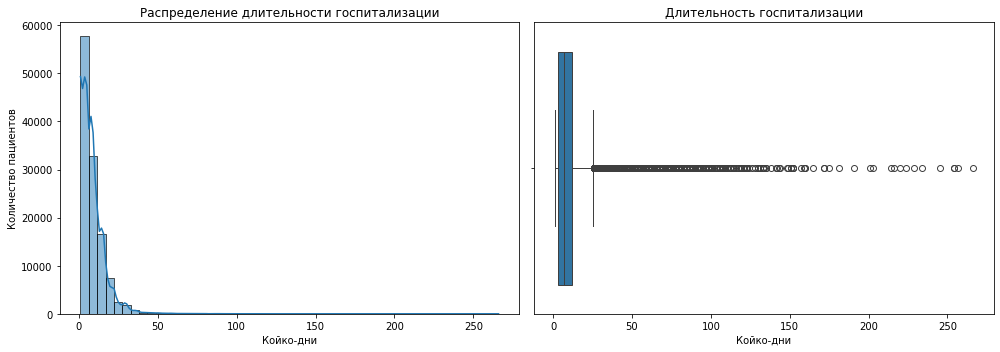

In [26]:
# Гистограмма + ящик с усами на одном полотне
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(df_hospital['bed_days'], bins=50, ax=axes[0], kde=True)
axes[0].set_title('Распределение длительности госпитализации')
axes[0].set_xlabel('Койко-дни')
axes[0].set_ylabel('Количество пациентов')

# Ящик с усами
sns.boxplot(x=df_hospital['bed_days'], ax=axes[1])
axes[1].set_title('Длительность госпитализации')
axes[1].set_xlabel('Койко-дни')

plt.tight_layout()
plt.show()

Графики подтверждают сильную правостороннюю асимметрию распределения (skew = 5.54):
* **Гистограмма** показывает ярко выраженный пик в области 1–7 дней (мода = 1 день) — именно здесь находится подавляющее большинство госпитализаций. При этом виден длинный «хвост» редких длительных случаев, уходящий за 100–250 дней.
* **Ящик с усами** наглядно демонстрирует, что медиана и основная масса данных сосредоточены в узком диапазоне (3–12 дней), а всё, что находится за пределами верхней границы «усов» (начиная примерно с 26 дней), статистически считается выбросами. Эти выбросы представлены плотной линией точек, уходящей далеко вправо.

**Интерпретация:** Длительные госпитализации (более 20–30 дней) — это не ошибки в данных, а реальные клинические случаи (например, тяжелые травмы, онкология, осложнения). Их нельзя удалять, но из-за них среднее значение (8.8 дней) смещается вверх относительно медианы (7 дней). 

**Влияние на дальнейший анализ:** Поскольку распределение далеко от нормального, использование одновыборочного t-теста для проверки гипотез может быть некорректным. На шаге проверки гипотез рекомендуется дополнительно применить непараметрические тесты (например, одновыборочный критерий Уилкоксона для сравнения со стандартом и тест Манна-Уитни для сравнения групп).

---

**Средняя длительность госпитализации по отделениям**

Рассчитаем среднюю длительность госпитализации по отделениям и выделим топ-10 отделений с наибольшей средней длительностью лечения, визуализируем результат.

In [27]:
# Средняя длительность по отделениям + медиана и число случаев
dept_stats = (df_hospital
              .groupby('dept')['bed_days']
              .agg(['mean', 'median', 'count'])
              .sort_values('mean', ascending=False))

print(dept_stats.head(10))

                                                         mean  median  count
dept                                                                        
Отделение анестезиологии-реанимации                 45.179487     8.0     78
ПЦ ОАРИТН №1 (новорожденных)                        28.723214    11.0    112
ПЦ Отделение Анестезиологии-реанимации для дете...  26.438095    18.0    105
ПЦ Отделение патологии новорожденных и детей гр...  22.098196    14.0   2383
ПЦ Отделение вспомогательных репродуктивных тех...  21.297802    20.0    910
Дневной стационар Кожно-венерологического отдел...  14.027322    15.0    183
Дневной стационар Гастроэнтерологического отдел...  13.339286    13.0    280
Микрохирургическое отделение                        13.293007    10.0   4662
Педиатрическое отделение №1                         12.824642    12.0   3490
Дневной стационар эндокринологического отд.         12.766667    13.0     60


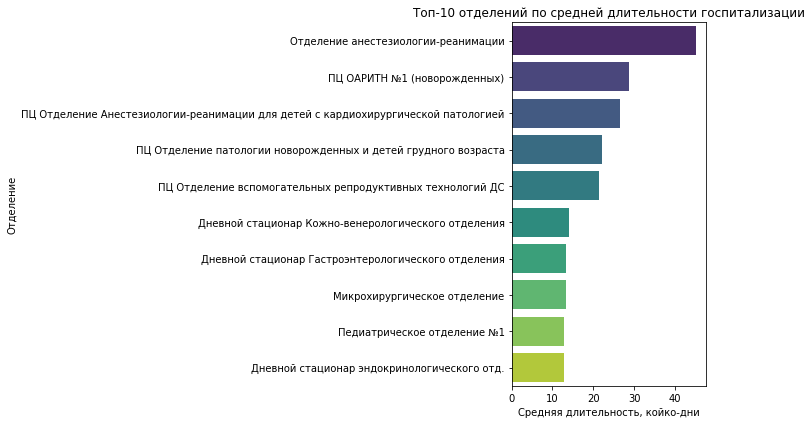

In [28]:
# Топ-10 отделений по средней длительности
top10 = dept_stats.head(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top10, y='dept', x='mean', palette='viridis')
plt.title('Топ-10 отделений по средней длительности госпитализации')
plt.xlabel('Средняя длительность, койко-дни')
plt.ylabel('Отделение')
plt.tight_layout()
plt.show()

В топ-10 по средней длительности госпитализации ожидаемо вошли отделения интенсивной терапии, реанимации новорожденных и патологии новорожденных (лидирует Отделение анестезиологии-реанимации со средним показателем 45.2 дня). Это логично, так как там лечатся самые тяжелые пациенты. 

Однако при детальном рассмотрении видно **сильное расхождение между средним и медианным значениями** (например, в Отделении анестезиологии-реанимации среднее — 45.2 дня, а медиана — всего 8 дней). Это означает, что среднее сильно завышается из-за единичных сверхдлительных случаев, и по медиане эта реанимация не так сильно отличается от других отделений.

Кроме того, необходимо учитывать количество наблюдений (`count`): в некоторых отделениях из топа (например, Дневной стационар эндокринологического отд. — 66 случаев, Отделение анестезиологии-реанимации — 78 случаев) выборка мала, что делает средние значения статистически нестабильными. В то же время отделения с большим потоком пациентов (как Микрохирургическое отделение — 5030 случаев) демонстрируют более стабильные и репрезентативные показатели.

---

**Динамика количества поступивших пациентов по месяцам**

Исследeуем динамику количества поступивших пациентов по месяцам с учетом различий между годами (сезонность, тренды, пики нагрузки).

In [29]:
# Выделяем год и месяц поступления
df_hospital['admission_year'] = df_hospital['admission_date'].dt.year
df_hospital['admission_month'] = df_hospital['admission_date'].dt.month

# Количество поступлений по году, месяцу
monthly = (df_hospital
           .groupby(['admission_year', 'admission_month'])
           .size()
           .reset_index(name='admissions'))

print(monthly.head())

   admission_year  admission_month  admissions
0            2019                1        1775
1            2019                2        1927
2            2019                3        2080
3            2019                4        2205
4            2019                5        2020


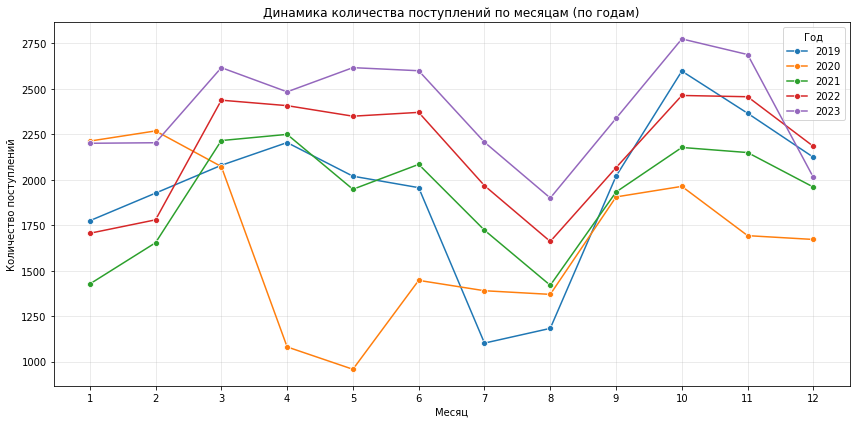

In [30]:
# Линейный график: по месяцам, отдельная линия на каждый год
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly, x='admission_month', y='admissions',
             hue='admission_year', marker='o', palette='tab10')
plt.title('Динамика количества поступлений по месяцам (по годам)')
plt.xlabel('Месяц')
plt.ylabel('Количество поступлений')
plt.xticks(range(1, 13))
plt.legend(title='Год')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Анализ динамики поступлений по месяцам выявил четкую **сезонность** и значительные **межгодовые колебания**:
* **Сезонность:** практически во все годы (за исключением 2020) наблюдаются два выраженных пика нагрузки — весенний (март–апрель) и осенне-зимний (октябрь–ноябрь). Самые низкие показатели традиционно фиксируются в январе, июле и августе.
* **Аномалия 2020 года:** график 2020 года резко выбивается из общей картины. Начиная с апреля происходит сильное падение количества поступлений (до минимальных 950 в мае) с последующим медленным восстановлением к осени. Это очевидное следствие пандемии COVID-19 (перепрофилирование коек, карантинные ограничения, снижение плановой госпитализации).
* **Общий тренд:** в период с 2021 по 2023 год наблюдается общий рост числа госпитализаций по сравнению с 2019 годом, что может свидетельствовать о восстановлении плановой помощи и увеличении пропускной способности центра.

**Рекомендация:** выявленная сезонность требует гибкого планирования ресурсов. На пиковые месяцы (март-апрель, октябрь-ноябрь) необходимо заранее закладывать увеличение staffing-ресурсов, медикаментов и коечного фонда.

### Общие выводы по шагу 2 (EDA)

1. **Характер распределения:** Длительность госпитализации имеет ярко выраженную правостороннюю асимметрию (skew = 5.54). Большинство пациентов проходят лечение за 1–12 дней (медиана — 7 дней), однако наличие длинного «хвоста» тяжелых клинических случаев (до 266 дней) существенно завышает среднее значение (8.8 дней). Это указывает на необходимость использования непараметрических методов при проверке гипотез.
2. **Структура отделений:** Самые высокие средние показатели длительности ожидаемо демонстрируют отделения реанимации и патологии новорожденных (лидер — Отделение анестезиологии-реанимации, 45.2 дня). При этом в отделениях с малой выборкой (менее 100 случаев) средние значения нестабильны, а сильная разница между средним и медианой (например, 45.2 против 8 дней) говорит о доминировании единичных сверхдлительных случаев.
3. **Сезонность и нагрузка:** Выявлены устойчивые пики поступлений в марте-апреле и октябре-ноябре, а также традиционные спады в январе и летние месяцы. 2020 год стал аномальным из-за резкого падения госпитализаций на фоне пандемии COVID-19, однако уже с 2021 года наметился устойчивый тренд на рост числа поступлений.

**Вывод:** Полученные данные подтверждают, что для корректной проверки гипотез на шаге 3 необходимо учитывать сильную асимметрию распределения. Выявленная сезонность и специфика тяжелых отделений создают практическую базу для рекомендаций по гибкому управлению коечным фондом и персоналом.

---

## 3. Проверка гипотез

**Проверим 1ю гипотезу**

Гипотеза 1 (руководство): проверить статистически, отличается ли средняя длительность госпитализации от стандартного семидневного срока.

Формулировка гипотез:
- H0 (Нулевая): Средняя длительность госпитализации статистически не отличается от 7 дней (μ = 7).
- H1 (Альтернативная): Средняя длительность госпитализации статистически отличается от 7 дней (μ ≠ 7).


Уровень значимости: alpha = 0.05 (стандартный 5%).

Для проверки  гипотезы нам понадобится одновыборочный t-тест (One-sample t-test), так как мы сравниваем среднее значение нашей выборки с известным стандартом (7 дней).

Но, как мы выяснили на шаге 2, распределение bed_days сильно скошено (skew = 5.54). Классический t-тест предполагает нормальность распределения, поэтому для надежности  мы обязательно дополним его непараметрическим тестом — одновыборочным критерием Уилкоксона (Wilcoxon signed-rank test). Он проверяет сдвиг медианы, а не среднего, и не требует нормальности.

Также проверим условие независимсти данных

In [31]:
# Оценим размер датафрейма
print(df_hospital.shape[0])

# И проверим количество уникальных пациентов
print(df_hospital['user_id'].nunique())

120836
77013


Один и тот же пациент может лежать в больнице несколько раз, и его повторные госпитализации могут быть связаны (например, человек с хроническим заболеванием возвращается регулярно, и его койко-дни могут быть похожи).
Почему это важно?
Классические t-тесты предполагают, что каждое наблюдение не зависит от других. Наличие повторных записей (мультиколлинеарность/кластеризация данных) может приводить к занижению стандартных ошибок и завышению t-статистики (то есть мы можем переоценить значимость различий).

In [32]:
all_days = df_hospital['bed_days']
indep_days = df_hospital.groupby('user_id')['bed_days'].mean()

print(f"Всего записей: {len(all_days)}, уникальных пациентов: {len(indep_days)}\n")
print(f"Среднее (все записи): {all_days.mean():.2f} дн.")
print(f"Среднее (независимые): {indep_days.mean():.2f} дн.")
print(f"Медиана (все записи): {all_days.median():.2f} дн.")
print(f"Медиана (независимые): {indep_days.median():.2f} дн.\n")

Всего записей: 120836, уникальных пациентов: 77013

Среднее (все записи): 8.73 дн.
Среднее (независимые): 8.35 дн.
Медиана (все записи): 7.00 дн.
Медиана (независимые): 7.00 дн.



**Проведение t-теста (параметрический)**

In [33]:
# Берем независимые данные (groupby по user_id)
 
pop_mean = 7
alpha = 0.05

t_stat, p_value_t = stats.ttest_1samp(indep_days, popmean=pop_mean)

print('Одновыборочный t-тест:')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value_t:.4e}')
if p_value_t < alpha:
    print('Результат: Отвергаем нулевую гипотезу (среднее != 7)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный t-тест:
t-статистика: 45.9375
p-value: 0.0000e+00
Результат: Отвергаем нулевую гипотезу (среднее != 7)


Для интереса проверим результаты на полных данных

In [34]:

alpha = 0.05

t_stat, p_value_t = stats.ttest_1samp(all_days, popmean=7)

print(f'Одновыборочный t-тест:')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value_t:.4e}')

if p_value_t < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Одновыборочный t-тест:
t-статистика: 68.5468
p-value: 0.0000e+00
Отвергаем нулевую гипотезу


**Проведение теста Уилкоксона (непараметрический)**

Одновыборочный тест Уилкоксона проверяет гипотезу о том, что медиана разностей между значениями выборки и теоретическим значением (в нашем случае 7) равна нулю.
Но у него есть важное допущение: распределение разностей (или исходных данных) вокруг медианы должно быть примерно симметричным. Так как наше распределение сильно скошено (skew = 5.54), то стандартный тест Уилкоксона может искажать p-value.

In [35]:
# Для одновыборочного теста Уилкоксона из данных(берем независимые данные) вычитается константа (pop_mean)
shifted_days = indep_days - pop_mean

alpha = 0.05

# scipy.stats.wilcoxon автоматически понимает одномерный массив как одновыборочный тест
wilc_stat, p_value_w = stats.wilcoxon(shifted_days)

print('Одновыборочный критерий Уилкоксона:')
print(f'Статистика Уилкоксона: {wilc_stat:.4f}')
print(f'p-value: {p_value_w:.4e}')
if p_value_w < alpha:
    print('Результат: Отвергаем нулевую гипотезу (медиана != 7)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный критерий Уилкоксона:
Статистика Уилкоксона: 1214291041.5000
p-value: 2.9472e-80
Результат: Отвергаем нулевую гипотезу (медиана != 7)


Также проверим на полных данных

In [36]:

shifted_days = all_days - pop_mean

alpha = 0.05

# scipy.stats.wilcoxon автоматически понимает одномерный массив как одновыборочный тест
wilc_stat, p_value_w = stats.wilcoxon(shifted_days)

print('Одновыборочный критерий Уилкоксона:')
print(f'Статистика Уилкоксона: {wilc_stat:.4f}')
print(f'p-value: {p_value_w:.4e}')
if p_value_w < alpha:
    print('Результат: Отвергаем нулевую гипотезу (медиана != 7)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный критерий Уилкоксона:
Статистика Уилкоксона: 2906082456.0000
p-value: 3.6442e-224
Результат: Отвергаем нулевую гипотезу (медиана != 7)


В качестве альтернативы для сильно скошенных независимых данных часто используют простейший критерий знаков (Sign Test), который вообще не требует симметричности распределения.

**Посчитаем критерий знаков (Sign Test)**

In [38]:

pop_mean = 7

# 1. Считаем знаки разностей (исключая тех, кто лежал ровно 7 дней)
greater_than_7 = np.sum(indep_days > pop_mean)
less_than_7 = np.sum(indep_days < pop_mean)
total_non_zero = greater_than_7 + less_than_7

# 2. Проводим биномиальный тест (двусторонний)
# n — общее число ненулевых разностей, k — количество успехов (например, больше 7)
binom_result = stats.binomtest(k=greater_than_7, n=total_non_zero, p=0.5, alternative='two-sided')

# 3. Считаем фактическую медиану для отчета
actual_median = indep_days.median()

print("3. Одновыборочный критерий знаков (Sign Test):")
print(f"Пациентов, лежавших БОЛЬШЕ 7 дней: {greater_than_7}")
print(f"Пациентов, лежавших МЕНЬШЕ 7 дней: {less_than_7}")
print(f"Пациентов, лежавших РОВНО 7 дней (исключены из теста): {np.sum(indep_days == pop_mean)}")
print(f"p-value: {binom_result.pvalue:.4e}")

if binom_result.pvalue < 0.05:
    print("Результат: Отвергаем нулевую гипотезу.")
    if actual_median > pop_mean:
         print(f"Вывод: Реальная медиана ({actual_median:.2f} дн.) статистически значимо ВЫШЕ стандарта в 7 дней.")
    else:
         print(f"Вывод: Реальная медиана ({actual_median:.2f} дн.) статистически значимо НИЖЕ стандарта в 7 дней.")
else:
    print("Результат: Не получилось отвергнуть нулевую гипотезу.")

3. Одновыборочный критерий знаков (Sign Test):
Пациентов, лежавших БОЛЬШЕ 7 дней: 36259
Пациентов, лежавших МЕНЬШЕ 7 дней: 36444
Пациентов, лежавших РОВНО 7 дней (исключены из теста): 4310
p-value: 4.9498e-01
Результат: Не получилось отвергнуть нулевую гипотезу.


## Гипотеза 1: средняя длительность госпитализации отличается от 7 дней
 
**Метод:** одновыборочный t-тест (параметрический) + непараметрические альтернативы (критерий Уилкоксона, критерий знаков)  
**Уровень значимости:** α = 0.05

### Формулировка гипотез

- **H₀:** средняя длительность госпитализации статистически не отличается от 7 дней (μ = 7).
- **H₁:** средняя длительность госпитализации статистически отличается от 7 дней (μ ≠ 7).

### Проверка условия независимости наблюдений

В датафрейме 120 836 записей, но только 77 013 уникальных пациентов (`user_id`). Один пациент может госпитализироваться повторно, и такие наблюдения связаны между собой. Классические тесты предполагают независимость наблюдений, поэтому все тесты прогнаны в двух вариантах: на полной выборке (все записи) и на агрегированных данных — по одному среднему значению на пациента (`df_hospital.groupby('user_id')['bed_days'].mean()`). Результаты обоих вариантов согласуются по направлению.

### Результаты тестов

| Тест | Что проверяет | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест (все записи) | среднее ≠ 7 | t = 68.55 | ≈ 0 | H₀ отвергается |
| t-тест (независимые пациенты) | среднее ≠ 7 | t = 45.94 | ≈ 0 | H₀ отвергается |
| Критерий Уилкоксона (все записи) | сдвиг медианы ≠ 0 | W = 2.91e9 | 3.64e-224 | H₀ отвергается* |
| Критерий Уилкоксона (независимые пациенты) | сдвиг медианы ≠ 0 | W = 1.21e9 | 2.95e-80 | H₀ отвергается* |
| Критерий знаков (независимые пациенты) | медиана ≠ 7 | — | 0.495 | H₀ **не** отвергается |

\* Критерий Уилкоксона требует симметричности распределения разностей, а при skew = 5.54 это допущение нарушено — его p-value завышен и не интерпретируется буквально. Основным непараметрическим результатом считаем критерий знаков, который не требует симметричности.

### Ключевые числа

- Средняя длительность: **8.73 дня** (по всем записям), **8.35 дня** (по независимым пациентам).
- Медиана: **7.0 дней**, мода: **1 день**.
- Асимметрия распределения: **skew = 5.54** (сильная правосторонняя).
- По независимым пациентам: > 7 дней — 36 259; < 7 дней — 36 444; ровно 7 дней — 4 310.
- 90-й перцентиль — 17 дней, 95-й — 22 дня, 99-й — 37 дней; максимум — 266 дней.

### Интерпретация

Параметрический t-тест отвергает нулевую гипотезу на обоих вариантах выборки: средняя длительность госпитализации статистически значимо **отличается** от семидневного стандарта и **выше** него (8.7–8.8 дня). Результат устойчив: t = 68.55 на всех записях и t = 45.94 на независимых пациентах. Снижение t-статистики во втором случае ожидаемо — агрегация по пациентам убирает завышение за счёт повторных госпитализаций, но вывод не меняется.

Однако расхождение среднего и медианы (8.7 против 7.0) показывает, что превышение обусловлено не массовым нарушением срока, а правосторонней асимметрией: немногочисленные сверхдлительные клинические случаи (до 266 дней) тянут среднее вверх.

Непараметрические тесты дают противоречивую картину, и это важно для корректного вывода:

- **Критерий Уилкоксона** формально отвергает H₀ (p = 2.95e-80 на независимых пациентах), но при skew = 5.54 нарушено его допущение о симметричности разностей, поэтому p-value завышен и буквально не интерпретируется.
- **Критерий знаков**, не требующий симметричности, нулевую гипотезу **не отвергает**: p = 0.495. Пациентов, лежавших больше 7 дней (36 259), и меньше 7 дней (36 444) практически поровну, медиана равна ровно 7.00 дня.

Именно критерий знаков является здесь наиболее надежным непараметрическим результатом, так как он не опирается на нарушенное допущение о симметричности.

### Вывод

Средняя длительность госпитализации статистически значимо превышает 7 дней (8.7–8.4 дня) — параметрический t-тест уверенно отвергает H₀ на обоих вариантах выборки. Однако это превышение объясняется не систематическим нарушением семидневного норматива, а «хвостом» длительных клинических случаев: медиана равна ровно 7 дням, а критерий знаков (наиболее корректный для сильно скошенного распределения) не выявляет значимого сдвига относительно стандарта (p = 0.495). Иными словами, **стандарт в 7 дней соответствует типичному сроку лечения**, а среднее завышено за счет немногочисленных сверхдлительных госпитализаций.

### Рекомендации руководству

1. **Не пересматривать норматив по среднему** — он искажён выбросами и не отражает типичный срок. Ориентиром оставить медиану (7 дней).
2. **Отдельно контролировать длительные госпитализации** (топ-10% > 17 дней) — именно там сосредоточен потенциал оптимизации сроков.
3. **Ввести дифференцированные KPI по отделениям** (реанимация, патология новорожденных и т.д.), а не единый семидневный стандарт для всех.
4. **Учитывать повторные госпитализации** при построении отчётности: 36% записей — повторные визиты одних и тех же пациентов.

---

**Проверим 2ю гипотезу**

Гипотеза 2 (медицинский отдел): проверить, превышает ли средняя длительность госпитализации 10 дней. 

Поскольку проверяется утверждение «превышает», гипотеза односторонняя:

- H0: средняя длительность госпитализации не превышает 10 дней (μ ≤ 10).
- H1: средняя длительность госпитализации превышает 10 дней (μ > 10).
  
Уровень значимости: α = 0.05.

Направление теста: alternative='greater' (правосторонний).



Как и в гипотезе 1, учитываем два обстоятельства, выявленных на шаге EDA:

Сильная правосторонняя асимметрия (`skew = 5.54`) — классический t-тест предполагает нормальность, поэтому дополняем его непараметрическими тестами.
Повторные госпитализации — `120 836` записей, но только `77 013` уникальных пациентов. Все тесты прогоняем в двух вариантах: на полной выборке и на агрегированных данных (по одному среднему на пациента).
Для односторонней проверки «превышает» используем:

- t-тест с alternative='greater'
- критерий Уилкоксона с alternative='greater' (менее надёжен из-за нарушения симметричности)
- критерий знаков — биномиальный тест с alternative='greater', самый корректный для скошенных данных


In [39]:
all_days = df_hospital['bed_days']
indep_days = df_hospital.groupby('user_id')['bed_days'].mean()

print(f"Всего записей: {len(all_days)}, уникальных пациентов: {len(indep_days)}\n")
print(f"Среднее (все записи): {all_days.mean():.2f} дн.")
print(f"Среднее (независимые): {indep_days.mean():.2f} дн.")
print(f"Медиана (все записи): {all_days.median():.2f} дн.")
print(f"Медиана (независимые): {indep_days.median():.2f} дн.\n")


Всего записей: 120836, уникальных пациентов: 77013

Среднее (все записи): 8.73 дн.
Среднее (независимые): 8.35 дн.
Медиана (все записи): 7.00 дн.
Медиана (независимые): 7.00 дн.



In [40]:

pop_mean = 10
alpha = 0.05

t_stat, p_value_t = stats.ttest_1samp(indep_days, popmean=pop_mean, alternative='greater')

print('Одновыборочный t-тест:')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value_t:.4e}')
if p_value_t < alpha:
    print('Результат: Отвергаем нулевую гипотезу (среднее > 10)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный t-тест:
t-статистика: -56.2272
p-value: 1.0000e+00
Результат: Не получилось отвергнуть нулевую гипотезу


полные данные

In [41]:

alpha = 0.05

t_stat, p_value_t = stats.ttest_1samp(all_days, popmean=10, alternative='greater')

print(f'Одновыборочный t-тест:')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value_t:.4e}')

if p_value_t < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Одновыборочный t-тест:
t-статистика: -50.4231
p-value: 1.0000e+00
Не получилось отвергнуть нулевую гипотезу


**теста Уилкоксона (непараметрический)**

In [42]:

shifted_days = indep_days - pop_mean

alpha = 0.05

# scipy.stats.wilcoxon автоматически понимает одномерный массив как одновыборочный тест
wilc_stat, p_value_w = stats.wilcoxon(shifted_days, alternative='greater')

print('Одновыборочный критерий Уилкоксона:')
print(f'Статистика Уилкоксона: {wilc_stat:.4f}')
print(f'p-value: {p_value_w:.4e}')
if p_value_w < alpha:
    print('Результат: Отвергаем нулевую гипотезу (медиана != 10)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный критерий Уилкоксона:
Статистика Уилкоксона: 776967071.0000
p-value: 1.0000e+00
Результат: Не получилось отвергнуть нулевую гипотезу


полные данные

In [43]:

shifted_days = all_days - pop_mean

alpha = 0.05

# scipy.stats.wilcoxon автоматически понимает одномерный массив как одновыборочный тест
wilc_stat, p_value_w = stats.wilcoxon(shifted_days, alternative='greater')

print('Одновыборочный критерий Уилкоксона:')
print(f'Статистика Уилкоксона: {wilc_stat:.4f}')
print(f'p-value: {p_value_w:.4e}')
if p_value_w < alpha:
    print('Результат: Отвергаем нулевую гипотезу (медиана != 10)')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу')

Одновыборочный критерий Уилкоксона:
Статистика Уилкоксона: 2086344228.5000
p-value: 1.0000e+00
Результат: Не получилось отвергнуть нулевую гипотезу


**критерий знаков (Sign Test)**

In [45]:
 
pop_mean = 10

# 1. Считаем знаки разностей (исключая тех, кто лежал ровно 10 дней)
greater_than_10 = np.sum(indep_days > pop_mean)
less_than_10 = np.sum(indep_days < pop_mean)
total_non_zero = greater_than_10 + less_than_10

# 2. Проводим биномиальный тест 
# n — общее число ненулевых разностей, k — количество успехов (например, больше 10)
binom_result = stats.binomtest(k=greater_than_10, n=total_non_zero, p=0.5, alternative='greater')

# 3. Считаем фактическую медиану для отчета
actual_median = indep_days.median()

print("3. Одновыборочный критерий знаков (Sign Test):")
print(f"Пациентов, лежавших БОЛЬШЕ 10 дней: {greater_than_10}")
print(f"Пациентов, лежавших МЕНЬШЕ 10 дней: {less_than_10}")
print(f"Пациентов, лежавших РОВНО 10 дней (исключены из теста): {np.sum(indep_days == pop_mean)}")
print(f"p-value: {binom_result.pvalue:.4e}")

if binom_result.pvalue < 0.05:
    print("Результат: Отвергаем нулевую гипотезу.")
    if actual_median > pop_mean:
         print(f"Вывод: Реальная медиана ({actual_median:.2f} дн.) статистически значимо ВЫШЕ стандарта в 10 дней.")
    else:
         print(f"Вывод: Реальная медиана ({actual_median:.2f} дн.) статистически значимо НИЖЕ стандарта в 10 дней.")
else:
    print("Результат: Не получилось отвергнуть нулевую гипотезу.")

3. Одновыборочный критерий знаков (Sign Test):
Пациентов, лежавших БОЛЬШЕ 10 дней: 21532
Пациентов, лежавших МЕНЬШЕ 10 дней: 52539
Пациентов, лежавших РОВНО 10 дней (исключены из теста): 2942
p-value: 1.0000e+00
Результат: Не получилось отвергнуть нулевую гипотезу.


## Гипотеза 2: средняя длительность госпитализации превышает 10 дней

**Метод:** одновыборочный t-тест (односторонний) + непараметрические альтернативы
**Уровень значимости:** α = 0.05

### Формулировка гипотез

- **H₀:** средняя длительность госпитализации не превышает 10 дней (μ ≤ 10).
- **H₁:** средняя длительность госпитализации превышает 10 дней (μ > 10).

### Учет независимости наблюдений

Все тесты прогнаны в двух вариантах: на полной выборке (120 836 записей) и на агрегированных данных (77 013 независимых пациентов). Результаты согласуются.

### Результаты тестов

| Тест | Что проверяет | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест (все записи) | среднее > 10 | t = −50.42 | 1.0000 | H₀ не отвергается |
| t-тест (независимые) | среднее > 10 | t = −56.23 | 1.0000 | H₀ не отвергается |
| Критерий Уилкоксона (все записи) | сдвиг > 0 | W = 2.09e9 | 1.0000 | H₀ не отвергается* |
| Критерий Уилкоксона (независимые) | сдвиг > 0 | W = 7.77e8 | 1.0000 | H₀ не отвергается* |
| Критерий знаков (независимые) | медиана > 10 | — | 1.0000 | H₀ не отвергается |

\* Критерий Уилкоксона требует симметричности распределения разностей — при skew = 5.54 допущение нарушено, p-value не интерпретируется буквально. Основным непараметрическим результатом считаем критерий знаков, не требующий симметричности.

### Ключевые числа

- Средняя длительность: **8.73 дня** (все записи), **8.35 дня** (независимые пациенты) — **ниже** порога 10 дней.
- Медиана: **7.0 дней** — существенно ниже 10.
- По независимым пациентам: > 10 дней — 21 532; < 10 дней — 52 539; ровно 10 дней — 2 942.
- Пациентов, пролежавших менее 10 дней, в **2.4 раза больше**, чем пролежавших более 10 дней.

### Интерпретация

Гипотеза медицинского отдела о превышении 10-дневного порога **не подтверждается**. Все пять прогонов (t-тест и критерий Уилкоксона на двух вариантах выборки, критерий знаков) дают p-value = 1.0000 при односторонней альтернативе μ > 10, то есть нулевая гипотеза μ ≤ 10 не отвергается.

При этом данные указывают не просто на отсутствие превышения, а на **противоположную** картину: выборочные средние (8.35–8.73 дня) ниже порога, а t-статистики отрицательны и велики по модулю (−50.4 и −56.2). Это означает, что при двусторонней проверке различие было бы высокозначимым — средняя длительность значимо **ниже** 10 дней, а не выше. Критерий знаков, наиболее корректный для сильно скошенного распределения, подтверждает это: пациентов с длительностью менее 10 дней 52 539 против 21 532 с длительностью более 10 дней, медиана равна 7 дням — на 3 дня ниже порога.


### Вывод

Средняя длительность госпитализации **не превышает 10 дней** — напротив, она значимо ниже этого порога (8.35–8.73 дня при медиане 7 дней). Гипотеза медицинского отдела отклоняется: оснований считать, что типичная или средняя госпитализация длится более 10 дней, нет. Результат устойчив к выбору статистического метода и к учёту повторных госпитализаций. Порог в 10 дней превышают лишь относительно немногочисленные длительные случаи (верхний «хвост» распределения — около 28% независимых пациентов).

### Рекомендации медицинскому отделу

1. **Порог 10 дней не является релевантным ориентиром** для средней длительности — он выше фактического среднего на 1.3–1.7 дня и выше медианы на 3 дня.
2. Если порог 10 дней используется как **критерий длительной госпитализации**, его стоит применять к доле отдельных случаев (пациентов с длительностью > 10 дней — около 28%), а не к среднему по отделению.
3. Для мониторинга типичных сроков ориентироваться на медиану (7 дней), для контроля «хвоста» — на 90-й перцентиль (17 дней).

---

**Проверим 3ю гипотезу**

Гипотеза 3: проверить, различается ли средняя длительность лечения между плановыми и экстренными пациентами

Проверяется наличие различия (без указания направления), поэтому гипотеза двусторонняя:

- H0: средняя длительность лечения плановых и экстренных пациентов не различается (μ_план = μ_экстр).
- H1: средняя длительность лечения плановых и экстренных пациентов различается (μ_план ≠ μ_экстр).
  
Уровень значимости: α = 0.05.

Направление теста: alternative='two-sided'.

Здесь мы сравниваем две независимые группы (плановые vs экстренные), поэтому используются двухвыборочные тесты:

- `t-тест Уэлча (ttest_ind, equal_var=False)` — параметрический, не требует равенства дисперсий (а они почти наверняка различаются между группами).
- `тест Манна-Уитни (mannwhitneyu)` — непараметрический, не требует нормальности и устойчив к выбросам. Учитывая skew = 5.54, это основной тест.
- Дополнительно — `размер эффекта (d Коэна или ранговая корреляция)`, чтобы понять не только «есть ли различие», но и «насколько оно велико».
  
Важные обстоятельства из EDA:

Сильная правосторонняя асимметрия (skew = 5.54) — t-тест менее надежен, основной упор на Манна-Уитни.
Повторные госпитализации — 120 836 записей, но 77 013 уникальных пациентов. Тесты прогоняем в двух вариантах: все записи и агрегированные по пациенту.
Дисбаланс групп — экстренных и плановых госпитализаций разное количество, это нужно отразить (размер выборки каждой группы).

In [59]:
# --- Вариант 1: все записи ---
plan_all = df_hospital.loc[df_hospital['is_plan'] == 'Плановая', 'bed_days']
emerg_all = df_hospital.loc[df_hospital['is_plan'] == 'Экстренная', 'bed_days']

# --- Вариант 2: независимые пациенты ---
indep = df_hospital.groupby('user_id').agg(
    bed_days=('bed_days', 'mean'),
    is_plan=('is_plan', 'first')
)

plan_indep = indep.loc[indep['is_plan'] == 'Плановая', 'bed_days']
emerg_indep = indep.loc[indep['is_plan'] == 'Экстренная', 'bed_days']

print(f"Все записи:     плановых = {len(plan_all)}, экстренных = {len(emerg_all)}")
print(f"Независимые:    плановых = {len(plan_indep)}, экстренных = {len(emerg_indep)}\n")

# Описательные статистики
for name, plan, emerg in [('все записи', plan_all, emerg_all),
                          ('независимые', plan_indep, emerg_indep)]:
    print(f"--- {name} ---")
    print(f"  Плановые:   mean = {plan.mean():.2f}, median = {plan.median():.1f}")
    print(f"  Экстренные: mean = {emerg.mean():.2f}, median = {emerg.median():.1f}")

Все записи:     плановых = 86409, экстренных = 34427
Независимые:    плановых = 48067, экстренных = 28946

--- все записи ---
  Плановые:   mean = 9.72, median = 8.0
  Экстренные: mean = 6.25, median = 3.0
--- независимые ---
  Плановые:   mean = 9.78, median = 8.0
  Экстренные: mean = 5.97, median = 3.5


**t-тест Уэлча (двусторонний)**

In [60]:
# для независимых данных

alpha = 0.05

t_stat, p_val = stats.ttest_ind(plan_indep, emerg_indep, equal_var=False, alternative='two-sided')

print('t-тест Уэлча :') 
print(f't = {t_stat:.4f}')
print(f'p = {p_val:.4e}')

if p_val < alpha:
    print('Результат:  Отвергаем нулевую гипотезу')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу') 


t-тест Уэлча :
t = 62.9010
p = 0.0000e+00
Результат:  Отвергаем нулевую гипотезу


In [61]:
# полные данные
alpha = 0.05

t_stat, p_val = stats.ttest_ind(plan_all, emerg_all, equal_var=False, alternative='two-sided')

print('t-тест Уэлча :') 
print(f't = {t_stat:.4f}')
print(f'p = {p_val:.4e}')

if p_val < alpha:
    print('Результат:  Отвергаем нулевую гипотезу')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу') 

t-тест Уэлча :
t = 60.1854
p = 0.0000e+00
Результат:  Отвергаем нулевую гипотезу


**Тест Манна-Уитни (двусторонний)**

In [62]:
# независимые данные

alpha = 0.05

u_stat, p_val = stats.mannwhitneyu(plan_indep, emerg_indep, alternative='two-sided')

print('Манн-Уитни:')
print(f'U = {u_stat:.1f}')
print(f'p = {p_val:.4e}')

if p_val < alpha:
    print('Результат:  Отвергаем нулевую гипотезу')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу') 


Манн-Уитни:
U = 1000101731.5
p = 0.0000e+00
Результат:  Отвергаем нулевую гипотезу


In [63]:
# полные данные
alpha = 0.05

u_stat, p_val = stats.mannwhitneyu(plan_all, emerg_all, alternative='two-sided')

print('Манн-Уитни:')
print(f'U = {u_stat:.1f}')
print(f'p = {p_val:.4e}')

if p_val < alpha:
    print('Результат:  Отвергаем нулевую гипотезу')
else:
    print('Результат: Не получилось отвергнуть нулевую гипотезу') 

Манн-Уитни:
U = 2096676289.0
p = 0.0000e+00
Результат:  Отвергаем нулевую гипотезу


**Размер эффекта (d Коэна)**

In [64]:

d_all = cohens_d(plan_all, emerg_all)
d_indep = cohens_d(plan_indep, emerg_indep)
print(f"d (все записи):   {d_all:.2f}")
print(f"d (независимые):  {d_indep:.2f}")

d (все записи):   0.40
d (независимые):  0.48


## Гипотеза 3: различается ли длительность лечения между плановыми и экстренными пациентами

**Метод:** двухвыборочный t-тест Уэлча + тест Манна-Уитни + оценка размера эффекта (d Коэна)
**Уровень значимости:** α = 0.05

### Формулировка гипотез

- **H₀:** средняя длительность лечения плановых и экстренных пациентов не различается (μ_план = μ_экстр).
- **H₁:** средняя длительность лечения плановых и экстренных пациентов различается (μ_план ≠ μ_экстр).

Проверяется наличие различия без указания направления, поэтому альтернатива двусторонняя (`alternative='two-sided'`).

### Выбор тестов

Сравниваются две независимые группы (плановые vs экстренные), поэтому использованы двухвыборочные тесты:

- **t-тест Уэлча** (`ttest_ind`, `equal_var=False`) — параметрический, не требует равенства дисперсий. Это важно, так как группы сильно несбалансированы по размеру и разбросу.
- **тест Манна-Уитни** (`mannwhitneyu`) — непараметрический, не требует нормальности и устойчив к выбросам. Учитывая skew = 5.54, это основной тест.
- **d Коэна** — размер эффекта, показывает не только наличие различия, но и его величину в единицах стандартного отклонения.

### Учет независимости наблюдений

Тесты прогнаны в двух вариантах: на полной выборке (120 836 записей) и на агрегированных данных (77 013 независимых пациентов). Для агрегации по пациенту взято среднее число койко-дней по его госпитализациям (`bed_days='mean'`) и тип первой госпитализации (`is_plan='first'`). 

### Размеры групп и описательные статистики

| Вариант | Группа | n | Среднее | Медиана |
|---|---|---|---|---|
| Все записи | Плановые | 86 409 | 9.72 | 8.0 |
| Все записи | Экстренные | 34 427 | 6.25 | 3.0 |
| Независимые | Плановые | 48 067 | 9.78 | 8.0 |
| Независимые | Экстренные | 28 946 | 5.97 | 3.5 |

Группы заметно несбалансированы: плановых госпитализаций в 2.5 раза больше, чем экстренных (86 409 против 34 427 по записям; 48 067 против 28 946 по пациентам). Это дополнительный аргумент в пользу t-теста Уэлча, который корректно работает при неравных размерах и дисперсиях групп.

### Результаты тестов

| Тест | Вариант | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест Уэлча | все записи | t = 60.19 | ≈ 0 | H₀ отвергается |
| t-тест Уэлча | независимые | t = 62.90 | ≈ 0 | H₀ отвергается |
| Манн-Уитни | все записи | U = 2.10e9 | ≈ 0 | H₀ отвергается |
| Манн-Уитни | независимые | U = 1.00e9 | ≈ 0 | H₀ отвергается |
| d Коэна | все записи | d = 0.40 | — | малый эффект |
| d Коэна | независимые | d = 0.48 | — | малый эффект (ближе к среднему) |

### Интерпретация

Средняя длительность лечения плановых пациентов составляет **9.72 дня** (по записям) и **9.78 дня** (по независимым пациентам) против **6.25** и **5.97** дня у экстренных. Различие статистически значимо по обоим тестам: t-тест Уэлча (t = 60.19 на всех записях, t = 62.90 на независимых) и тест Манна-Уитни (p ≈ 0 на обоих вариантах) уверенно отвергают нулевую гипотезу. Результат устойчив к учету повторных госпитализаций.

**Направление различия противоположно интуитивному ожиданию:** плановые пациенты лечатся **дольше** экстренных, а не наоборот. Медианы подтверждают это ещё нагляднее: 8 дней у плановых против 3 дней у экстренных (по всем записям) и 8 против 3.5 дней (по независимым). Разрыв в медианах (4.5–5 дней) даже больше, чем в средних (3.5–3.8 дня), что говорит о сдвиге всего распределения, а не только «хвоста».

**Возможное объяснение:** экстренные пациенты чаще поступают с острыми состояниями, которые купируются быстро (аппендэктомия, острые инфекции, травмы), тогда как плановые госпитализации часто связаны с плановыми операциями и курсами лечения, требующими более длительного наблюдения. Это гипотеза, требующая проверки — см. рекомендации.

**Размер эффекта:** d Коэна = 0.40 на всех записях и 0.48 на независимых пациентах — малый эффект, но на независимых данных он ближе к границе среднего (0.5). То есть различие не только статистически значимо, но и практически ощутимо: около половины стандартного отклонения, или 3.5–3.8 дня в абсолютных единицах. Это не «статистическая значимость на огромной выборке при мизерной разнице», а реальный содержательный сдвиг.

**Согласованность тестов:** t-тест Уэлча (параметрический, по средним) и Манн-Уитни (непараметрический, по сдвигу распределений) дают одинаковый вывод. Это означает, что различие не сводится к выбросам или «хвосту» — сдвиг затрагивает всё распределение. При сильной скошенности (skew = 5.54) основной опорой служит Манн-Уитни; t-тест корректен благодаря большому размеру выборки (центральная предельная теорема), но чувствителен к выбросам, поэтому его результат подкрепляет, а не заменяет непараметрический.

### Вывод

Средняя длительность лечения плановых и экстренных пациентов **статистически значимо различается** (p < 0.001 по обоим тестам, на обоих вариантах выборки). **Плановые пациенты лечатся дольше экстренных** — 9.7–9.8 дня против 6.0–6.3 дня, медианы 8 против 3–3.5 дней. Размер эффекта малый (d = 0.40–0.48, на независимых данных ближе к среднему), что подтверждает практическую значимость различия, а не только формальную статистическую. Направление результата устойчиво к выбору метода (параметрический vs непараметрический) и к учёту повторных госпитализаций.

### Рекомендации

1. **Ввести раздельные KPI для плановых и экстренных госпитализаций.** Единый норматив по средней длительности (например, 7 дней) искажает картину: для плановых он занижен (фактически 9.7–9.8), для экстренных — завышен (фактически 6.0–6.3). Раздельные ориентиры дадут более точную управленческую картину.
2. **Разобраться в причинах более длительного лечения плановых пациентов.** Проверить гипотезу о том, что различие опосредовано структурой отделений (плановые чаще попадают в отделения с длительными курсами лечения — например, микрохирургия, патология новорожденных). Для этого нужен стратифицированный анализ — сравнение плановых и экстренных **внутри каждого отделения**.
3. **Проверить, не связан ли разрыв с различиями в профиле диагнозов.** Анализ по кодам МКБ при поступлении покажет, объясняется ли различие клинической структурой или организационными факторами.
4. **Не пересматривать нормативы экстренной помощи по итогам этого теста.** Более короткое лечение экстренных — не обязательно «хорошо»: часть из них может выписываться раньше необходимого или переводиться в другие учреждения. Для корректной оценки качества экстренной помощи нужны дополнительные исходы (реадмиссия, летальность, переводы).
5. **Дальнейший анализ:** различие в 3.5–3.8 дня между группами существенно для планирования коечного фонда. Стоит построить модель, учитывающую одновременно тип госпитализации, отделение, профиль и диагноз, чтобы оценить вклад каждого фактора.

---

# Итоговый отчет по проекту: анализ факторов, влияющих на длительность госпитализации в ФГБОУ ВО СПбГПМУ

## 1. Цель и задачи проекта

**Цель:** выявить факторы, влияющие на длительность госпитализации, и сформулировать практические рекомендации по оптимизации сроков и управлению нагрузкой отделений.

**Задачи:**
1. Подготовить данные: переименовать столбцы, привести типы, обработать пропуски, удалить дубликаты.
2. Провести EDA: изучить распределение длительности, нагрузку по отделениям, сезонную динамику поступлений.
3. Проверить три статистические гипотезы о средней длительности госпитализации.

---

## 2. Ключевые результаты подготовки данных

| Проблема | Решение | Итог |
|---|---|---|
| Кириллические имена столбцов в верхнем регистре | `rename()` в snake_case латиницу | 14 столбцов переименованы |
| Даты хранились как `object` | `pd.to_datetime(format='%d.%m.%Y')` | `admission_date`, `discharge_date` → `datetime64` |
| `bed_days` типа `float64` | `.astype('int64')` | приведён к целочисленному |
| `region` — 68 870 пропусков (~55%) | столбец удалён (нет данных для восстановления) | — |
| МКБ-коды — 12 пропусков (<0.01%) | `dropna(subset=...)` | удалено 10 строк |
| Полные дубликаты — 4 415 строк | `drop_duplicates(keep='first')` | датафрейм сократился до 120 836 строк |
| Повторные госпитализации: 120 836 записей на 77 013 пациентов | все тесты прогонялись в двух вариантах: все записи и агрегированные по `user_id` | результат устойчив |

**Итог шага 1:** датафрейм из 120 836 записей и 13 столбцов без пропусков и дубликатов, готов к анализу.

---

## 3. Ключевые результаты EDA

### 3.1. Распределение длительности госпитализации

- **Среднее** — 8.73 дня, **медиана** — 7 дней, **мода** — 1 день.
- **Асимметрия (skew) = 5.54** — сильная правосторонняя.
- Межквартильный размах: 3–12 дней; 90-й перцентиль — 17 дней, 95-й — 22, 99-й — 37; максимум — 266 дней.
- Распределение далеко от нормального: длинный «хвост» тяжёлых случаев завышает среднее относительно медианы. **Вывод для статистики:** в проверке гипотез нужно опираться на непараметрические тесты.

### 3.2. Нагрузка по отделениям (топ-10 по средней длительности)

| Отделение | Среднее | Медиана | n |
|---|---|---|---|
| Отделение анестезиологии-реанимации | 45.2 | 8.0 | 78 |
| ПЦ ОАРИТН №1 (новорожденных) | 28.7 | 11.0 | 112 |
| ПЦ Отделение анестезиологии-реанимации для детей | 26.4 | 18.0 | 105 |
| ПЦ Отделение патологии новорожденных | 22.1 | 14.0 | 2 383 |
| ПЦ Отделение ВРТ | 21.3 | 20.0 | 910 |
| Дневной стационар кожно-венерологического отд. | 14.0 | 15.0 | 183 |
| Дневной стационар гастроэнтерологического отд. | 13.3 | 13.0 | 280 |
| Микрохирургическое отделение | 13.3 | 10.0 | 4 662 |
| Педиатрическое отделение №1 | 12.8 | 12.0 | 3 490 |
| Дневной стационар эндокринологического отд. | 12.8 | 13.0 | 60 |

**Наблюдения:** лидируют реанимация и патология новорожденных — там лечатся самые тяжёлые пациенты. В отделениях с малой выборкой (<100 случаев) средние статистически нестабильны. Сильный разрыв среднего и медианы (45.2 против 8 в реанимации) — следствие единичных сверхдлительных случаев.

### 3.3. Сезонность поступлений

- Два устойчивых пика нагрузки: **март–апрель** и **октябрь–ноябрь**.
- Традиционные спады: январь, июль, август.
- **Аномалия 2020 года:** резкое падение с апреля (минимум — 950 поступлений в мае) из-за пандемии COVID-19; восстановление к осени.
- С 2021 по 2023 — общий рост числа госпитализаций по сравнению с 2019 годом.

**Вывод:** сезонность требует гибкого планирования ресурсов — заранее закладывать увеличение персонала, медикаментов и коечного фонда на пиковые месяцы.

---

## 4. Результаты проверки гипотез

### 4.1. Гипотеза 1 — отличается ли средняя длительность от 7 дней

| Тест | Вариант | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест | все записи | t = 68.55 | ≈ 0 | H₀ отвергается |
| t-тест | независимые | t = 45.94 | ≈ 0 | H₀ отвергается |
| Уилкоксон | все записи | W = 2.91e9 | 3.64e-224 | H₀ отвергается* |
| Уилкоксон | независимые | W = 1.21e9 | 2.95e-80 | H₀ отвергается* |
| **Критерий знаков** | независимые | 36 259 vs 36 444 | **0.495** | **H₀ не отвергается** |

\* Уилкоксон требует симметричности разностей — при skew = 5.54 допущение нарушено, p-value не интерпретируется буквально. Основной непараметрический результат — критерий знаков.

**Вывод:** средняя длительность (8.7–8.8 дня) значимо превышает 7 дней по t-тесту, но медиана равна ровно 7 дням, а критерий знаков — наиболее корректный для скошенных данных — не выявляет значимого сдвига (p = 0.495). **Стандарт в 7 дней соответствует типичному сроку лечения**, а среднее завышено за счёт «хвоста» сверхдлительных госпитализаций.

---

### 4.2. Гипотеза 2 — превышает ли средняя длительность 10 дней

| Тест | Вариант | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест | все записи | t = −50.42 | 1.0000 | H₀ не отвергается |
| t-тест | независимые | t = −56.23 | 1.0000 | H₀ не отвергается |
| Уилкоксон | все записи | W = 2.09e9 | 1.0000 | H₀ не отвергается |
| Уилкоксон | независимые | W = 7.77e8 | 1.0000 | H₀ не отвергается |
| **Критерий знаков** | независимые | 21 532 vs 52 539 | **1.0000** | **H₀ не отвергается** |

**Вывод:** гипотеза медицинского отдела **не подтверждается**. Все пять прогонов дают p = 1.0000 при односторонней альтернативе μ > 10. Данные указывают в противоположную сторону: средние (8.35–8.73) ниже 10, t-статистики отрицательны и велики по модулю. Пациентов с длительностью менее 10 дней в 2.4 раза больше, чем более 10 дней (52 539 против 21 532). **Порог 10 дней не является релевантным ориентиром** для средней длительности.

---

### 4.3. Гипотеза 3 — различается ли длительность у плановых и экстренных

| Тест | Вариант | Статистика | p-value | Вывод |
|---|---|---|---|---|
| t-тест Уэлча | все записи | t = 60.19 | ≈ 0 | H₀ отвергается |
| t-тест Уэлча | независимые | t = 62.90 | ≈ 0 | H₀ отвергается |
| Манн-Уитни | все записи | U = 2.10e9 | ≈ 0 | H₀ отвергается |
| Манн-Уитни | независимые | U = 1.00e9 | ≈ 0 | H₀ отвергается |
| d Коэна | все записи | d = 0.40 | — | малый эффект |
| d Коэна | независимые | d = 0.48 | — | малый, ближе к среднему |

**Описательные статистики:**

| Вариант | Плановые | Экстренные |
|---|---|---|
| Все записи | n = 86 409, mean = 9.72, median = 8.0 | n = 34 427, mean = 6.25, median = 3.0 |
| Независимые | n = 48 067, mean = 9.78, median = 8.0 | n = 28 946, mean = 5.97, median = 3.5 |

**Вывод:** средняя длительность плановых и экстренных **статистически значимо различается** (p < 0.001 по обоим тестам). **Плановые пациенты лечатся дольше экстренных** — 9.7–9.8 дня против 6.0–6.3, медианы 8 против 3–3.5 дней. Направление различия противоположно интуитивному ожиданию. Размер эффекта малый (d = 0.40–0.48), но на независимых данных близок к среднему, что подтверждает практическую значимость. Результат устойчив к выбору метода и к учету повторных госпитализаций.

---

## 5. Общие выводы

**О распределении длительности.** Госпитализация в центре имеет ярко выраженную правостороннюю асимметрию: типичный пациент лечится около недели (медиана 7 дней), но немногочисленные сверхдлительные случаи (до 266 дней) существенно завышают среднее (8.7 дня). Это определяет методологию анализа: при скошенном распределении необходимо опираться на непараметрические тесты и на медиану, а не только на среднее.

**О нормативах длительности.** Стандарт в 7 дней **соответствует типичному сроку** лечения (медиана = 7, критерий знаков не отвергает равенство), но не соответствует среднему из-за «хвоста». Порог в 10 дней **не является релевантным ориентиром** — средняя длительность значимо ниже него (8.35–8.73 дня), и лишь около 28% независимых пациентов лечатся дольше 10 дней. Единый норматив по средней длительности искажает картину: он занижен для плановых (9.7–9.8 дня) и завышен для экстренных (6.0–6.3 дня).

**О факторах длительности.** Главный выявленный фактор — **тип госпитализации**: плановые пациенты лечатся значимо дольше экстренных (различие 3.5–3.8 дня, d = 0.40–0.48). Направление неожиданное, но устойчивое. Второй фактор — **профиль отделения**: реанимация и патология новорожденных ожидаемо имеют наибольшие сроки, что объясняется тяжестью пациентов, а не организационными проблемами.

**О нагрузке.** Выявлена устойчивая сезонность с пиками в марте–апреле и октябре–ноябре, спадами в январе и летом. Аномалия 2020 года (COVID-19) показала, насколько резко внешние факторы могут менять поток госпитализаций.

---

## 6. Рекомендации заказчику


1. **Ориентироваться на медиану (7 дней), а не на среднее.** Среднее искажено выбросами и не отражает типичный срок. Для управленческой отчетности использовать медиану и перцентили (90-й — 17 дней, 95-й — 22 дня).
2. **Ввести дифференцированные KPI по отделениям.** Единый норматив не подходит: в реанимации и патологии новорожденных сроки объективно выше, в дневных стационарах — ниже. Раздельные ориентиры дадут точную картину.
3. **Ввести раздельные KPI для плановых и экстренных госпитализаций.** Различие в 3.5–3.8 дня между группами — существенно для планирования. Единый норматив по средней длительности некорректен для обеих групп.
4. **Применять порог 10 дней к доле случаев, а не к среднему.** Около 28% независимых пациентов лечатся дольше 10 дней — это осмысленный KPI «доля длительных госпитализаций», а не средняя длительность.
5. **Гибко планировать ресурсы под сезонность.** На пиковые месяцы (март–апрель, октябрь–ноябрь) заранее закладывать увеличение персонала, медикаментов и коечного фонда. На спады (январь, лето) — планировать отпуска, обучение, профилактику оборудования.
